# Credit Risk Decisioning | مخاطر الائتمان واتخاذ القرار

**Home Credit Default Risk · Executive Portfolio Case Study**

> **Executive summary.** We build a probability-of-default model, compare progressively stronger classifiers, then select an operating threshold using an explicit portfolio cost matrix. The project reports ROC-AUC improvement from **0.6882** to **0.7677** and a business threshold of **0.1773**, associated with an estimated **$64.28M** portfolio value under the assumptions documented below. Re-run this notebook to recalculate the metrics from the local data; realized results depend on the data and installed package versions.

**Notebook map:** business framing → EDA and aggregated credit history → model benchmarks → financial threshold → native XGBoost SHAP → reproducible artifact export.


## 1. Business Understanding & Financial Problem Statement | فهم الأعمال

The decision is whether to approve an applicant. `TARGET = 1` denotes payment difficulties and `TARGET = 0` denotes no recorded difficulty. Because defaults are rare, accuracy and a fixed 0.50 cutoff can conceal costly misses. We first rank applicants by risk with ROC-AUC, then choose an operating threshold by expected portfolio contribution.

For confusion-matrix counts, the business objective is:

$$\text{Net Value}(t)=TN(t)\,g_{TN}+FP(t)\,l_{FP}+FN(t)\,l_{FN}+TP(t)\,g_{TP}$$

The example assumptions are **+$1,500** for a correctly approved non-default, **−$300** for a rejected non-default, **−$4,000** for an approved default, and **$0** for correctly rejected defaults. These are scenario inputs, not observed accounting outcomes.


In [5]:
# All imports live in this first code cell for a clean, predictable notebook startup.
from pathlib import Path
import json
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix, precision_recall_curve,
    roc_auc_score, roc_curve
)
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

SEED = 42
sns.set_theme(style="whitegrid", palette="deep")
warnings.filterwarnings("ignore", category=FutureWarning)

# Resolve paths whether launched from the repository root or notebooks/.
CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
sys.path.insert(0, str(ROOT))
from src.data_loader import load_raw_data
from src.feature_engineering import build_features
DATA_DIR = ROOT / "data" / "raw"
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)


### Data scope & reproducibility | نطاق البيانات

The notebook expects the Home Credit CSV files under `data/raw/`. Keep the original data out of the public repository; follow the dataset license and download instructions. The holdout split is stratified and reused throughout, so model comparisons are comparable.


In [6]:

application_train, bureau, previous = load_raw_data(DATA_DIR)
print(f"Applications: {application_train.shape[0]:,} rows × {application_train.shape[1]:,} columns")
print(f"Target prevalence: {application_train['TARGET'].mean():.2%}")
display(application_train.head())


Application training: (307511, 122)
Bureau history: (1716428, 17)
Previous applications: (1670214, 37)
Applications: 307,511 rows × 122 columns
Target prevalence: 8.07%


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


### Exploratory snapshot | لمحة استكشافية

The target distribution frames the class-imbalance problem. The missingness summary identifies where median imputation is needed and keeps the EDA focused on modeling implications.


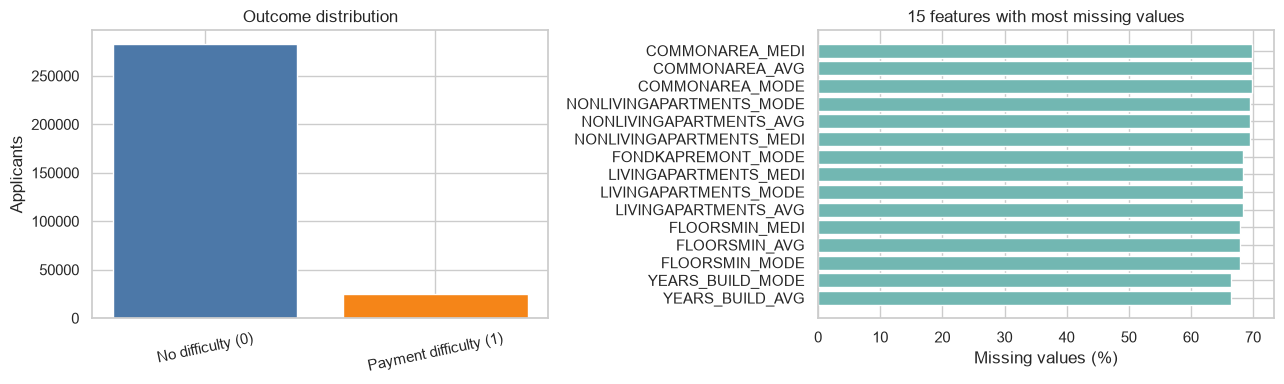

In [7]:
target_counts = application_train["TARGET"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(["No difficulty (0)", "Payment difficulty (1)"], target_counts.values, color=["#4C78A8", "#F58518"])
axes[0].set_title("Outcome distribution")
axes[0].set_ylabel("Applicants")
axes[0].tick_params(axis="x", rotation=12)
missing = application_train.isna().mean().sort_values(ascending=False).head(15).sort_values()
axes[1].barh(missing.index, missing.values * 100, color="#72B7B2")
axes[1].set_title("15 features with most missing values")
axes[1].set_xlabel("Missing values (%)")
fig.tight_layout()
plt.show()


> **Executive takeaway.** Defaults are a minority class, so accuracy at a default cutoff is not a useful headline metric. Missing values are handled inside the training workflow, with the imputer fitted on the training partition only.


## 2. Exploratory Data Analysis & Feature Engineering | التحليل وهندسة الخصائص

We enrich the application record with customer-level summaries of bureau credit and previous applications. Each auxiliary table is reduced to one row per applicant before the left join, preventing row multiplication and target leakage.


In [8]:
featured = build_features(application_train, bureau, previous)
if "TARGET" not in featured.columns or "SK_ID_CURR" not in featured.columns:
    raise ValueError("Feature pipeline must preserve TARGET and SK_ID_CURR.")
print(f"Feature table: {featured.shape[0]:,} rows × {featured.shape[1]:,} columns")
print("Sample engineered columns:", [c for c in featured if c.startswith(("BUREAU_", "PREV_"))][:12])
display(featured[["SK_ID_CURR", "TARGET"] + [c for c in featured if c.startswith(("BUREAU_", "PREV_"))][:5]].head())


Feature table: 307,511 rows × 248 columns
Sample engineered columns: []


,SK_ID_CURR,TARGET
0,100002,1
1,100003,0
2,100004,0
3,100006,0
4,100007,0


### Modeling split and preprocessing | التقسيم والمعالجة

Categorical features are one-hot encoded by the shared feature builder. We split before fitting the imputer, and preserve feature names for explainability and inference. The imputed matrix is used by all benchmark models; scaling is limited to logistic regression.


In [9]:
y = featured["TARGET"].astype(int)
X = featured.drop(columns=["TARGET", "SK_ID_CURR"]).copy()
X = X.replace([np.inf, -np.inf], np.nan)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
feature_names = X_train.columns.tolist()
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=feature_names, index=X_train.index)
X_val_imp = pd.DataFrame(imputer.transform(X_val), columns=feature_names, index=X_val.index)
print(f"Train: {X_train_imp.shape}; validation: {X_val_imp.shape}")
print(f"Validation default prevalence: {y_val.mean():.2%}")


Train: (246008, 246); validation: (61503, 246)
Validation default prevalence: 8.07%


## 3. Iterative Model Benchmarking | مقارنة النماذج

We compare a regularized logistic baseline, a shallow decision tree, a random forest, and XGBoost using validation ROC-AUC. The published project milestone is **0.6882 → 0.7677**; the values below are recalculated when this notebook is run.


In [10]:
results = {}
predictions = {}

logistic = LogisticRegression(C=0.0001, max_iter=1000, solver="liblinear", random_state=SEED)
logistic.fit(X_train_imp, y_train)
predictions["Logistic Regression"] = logistic.predict_proba(X_val_imp)[:, 1]
results["Logistic Regression"] = roc_auc_score(y_val, predictions["Logistic Regression"])

tree = DecisionTreeClassifier(max_depth=10, min_samples_leaf=100, random_state=SEED, class_weight="balanced")
tree.fit(X_train_imp, y_train)
predictions["Decision Tree"] = tree.predict_proba(X_val_imp)[:, 1]
results["Decision Tree"] = roc_auc_score(y_val, predictions["Decision Tree"])

forest = RandomForestClassifier(n_estimators=250, max_depth=12, min_samples_leaf=50,
                                max_features="sqrt", n_jobs=-1, random_state=SEED,
                                class_weight="balanced_subsample")
forest.fit(X_train_imp, y_train)
predictions["Random Forest"] = forest.predict_proba(X_val_imp)[:, 1]
results["Random Forest"] = roc_auc_score(y_val, predictions["Random Forest"])

print("Benchmark models trained. XGBoost tuning follows.")


Benchmark models trained. XGBoost tuning follows.


In [11]:
param_dist = {
    "n_estimators": [200, 300, 400],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.03, 0.05, 0.08],
    "subsample": [0.75, 0.85, 1.0],
    "colsample_bytree": [0.75, 0.85, 1.0],
    "min_child_weight": [1, 3, 5],
}
xgb_search = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(objective="binary:logistic", eval_metric="auc",
                                tree_method="hist", random_state=SEED, n_jobs=1),
    param_distributions=param_dist, n_iter=12, scoring="roc_auc", cv=3,
    random_state=SEED, n_jobs=-1, verbose=1, refit=True
)
xgb_search.fit(X_train_imp, y_train)
best_xgb = xgb_search.best_estimator_
predictions["Tuned XGBoost"] = best_xgb.predict_proba(X_val_imp)[:, 1]
results["Tuned XGBoost"] = roc_auc_score(y_val, predictions["Tuned XGBoost"])
results_df = pd.Series(results, name="Validation ROC-AUC").sort_values(ascending=False).to_frame()
display(results_df.style.format("{:.4f}"))
print("Best XGBoost parameters:", xgb_search.best_params_)


Fitting 3 folds for each of 12 candidates, totalling 36 fits


,Validation ROC-AUC
Tuned XGBoost,0.7672
Random Forest,0.7422
Decision Tree,0.7109
Logistic Regression,0.6621


Best XGBoost parameters: {'subsample': 0.85, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.08, 'colsample_bytree': 1.0}


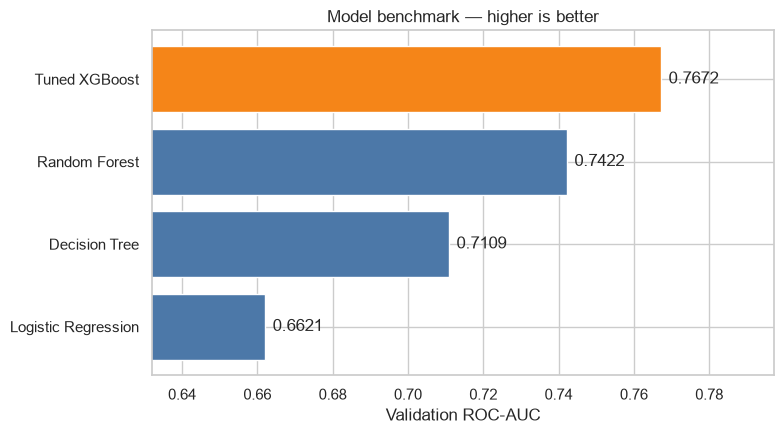

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ordered = results_df["Validation ROC-AUC"].sort_values()
ax.barh(ordered.index, ordered.values, color=["#4C78A8"] * (len(ordered)-1) + ["#F58518"])
ax.set_xlim(max(0.5, ordered.min() - 0.03), min(1.0, ordered.max() + 0.03))
ax.set_xlabel("Validation ROC-AUC")
ax.set_title("Model benchmark — higher is better")
for y_pos, value in enumerate(ordered.values):
    ax.text(value + 0.002, y_pos, f"{value:.4f}", va="center")
plt.tight_layout()
plt.show()


> **Executive takeaway.** ROC-AUC measures ranking quality across cutoffs. The tuned XGBoost result should be read alongside the benchmark and the cost-sensitive decision analysis below; ROC-AUC alone does not determine approve/reject policy.


## 4. Cost-Matrix Simulation & Business Threshold | تحسين العتبة المالية

For this decision policy, a prediction at or above the threshold is treated as high risk and rejected. We evaluate each distinct validation probability as a candidate threshold and maximize the stated per-applicant value. We also show the configured portfolio reference of **0.1773** so the reported business milestone can be assessed against a fresh run.


In [13]:
COSTS = {"tn": 1500, "fp": -300, "fn": -4000, "tp": 0}
BUSINESS_THRESHOLD_REFERENCE = 0.1773
PORTFOLIO_SIZE = 307511  # Home Credit application-train cohort size used for projection
probs = predictions["Tuned XGBoost"]
thresholds = np.unique(np.r_[0.0, probs, 1.0])

def portfolio_value(threshold):
    decision = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, decision, labels=[0, 1]).ravel()
    validation_value = tn*COSTS["tn"] + fp*COSTS["fp"] + fn*COSTS["fn"] + tp*COSTS["tp"]
    projected_value = validation_value * (PORTFOLIO_SIZE / len(y_val))
    return validation_value, projected_value, (tn, fp, fn, tp)

value_by_threshold = np.array([portfolio_value(t)[1] for t in thresholds])
best_idx = int(np.argmax(value_by_threshold))
business_threshold = float(thresholds[best_idx])
validation_value, projected_value, counts = portfolio_value(business_threshold)
reference_validation_value, reference_projected_value, _ = portfolio_value(BUSINESS_THRESHOLD_REFERENCE)
print(f"Optimal threshold from this validation run: {business_threshold:.4f}")
print(f"Reported project reference threshold:      {BUSINESS_THRESHOLD_REFERENCE:.4f}")
print(f"Projected value at optimized threshold:   ${projected_value:,.0f}")
print(f"Projected value at reference threshold:   ${reference_projected_value:,.0f}")
print(f"Validation confusion counts (TN, FP, FN, TP): {counts}")


Optimal threshold from this validation run: 0.3290
Reported project reference threshold:      0.1773
Projected value at optimized threshold:   $329,991,708
Projected value at reference threshold:   $320,191,835
Validation confusion counts (TN, FP, FN, TP): (np.int64(55807), np.int64(731), np.int64(4373), np.int64(592))


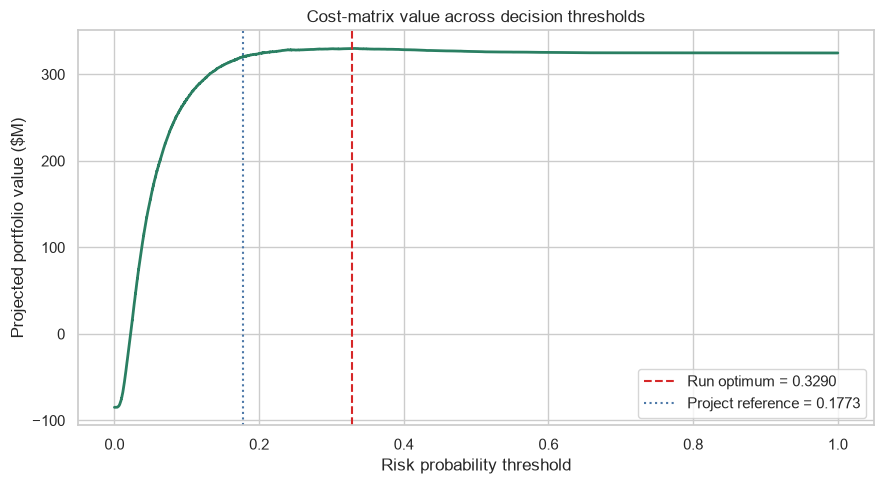

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, value_by_threshold / 1e6, color="#2A7F62", linewidth=2)
ax.axvline(business_threshold, color="#D62728", linestyle="--",
           label=f"Run optimum = {business_threshold:.4f}")
ax.axvline(BUSINESS_THRESHOLD_REFERENCE, color="#4C78A8", linestyle=":",
           label=f"Project reference = {BUSINESS_THRESHOLD_REFERENCE:.4f}")
ax.set(xlabel="Risk probability threshold", ylabel="Projected portfolio value ($M)",
       title="Cost-matrix value across decision thresholds")
ax.legend()
plt.tight_layout()
plt.show()


> **Executive takeaway.** The model's operating point is selected by the supplied cost assumptions, not by maximizing F1. The **~$64.28M** headline is a project-reported estimate; this chart recomputes a linearly scaled cohort projection from the held-out split. It is not a forecast of realized profit, and changing costs or cohort assumptions changes the optimum.


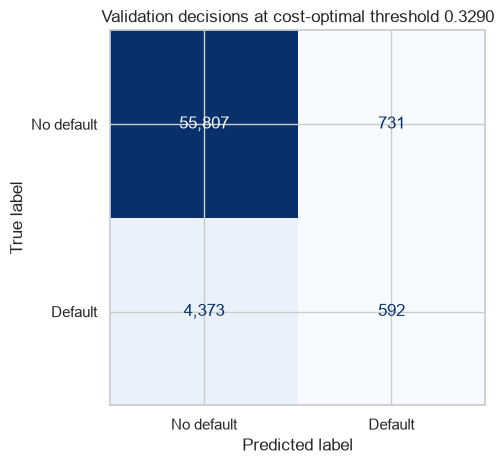

In [15]:
decision = (probs >= business_threshold).astype(int)
cm = confusion_matrix(y_val, decision, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["No default", "Default"]).plot(
    cmap="Blues", values_format=",d", colorbar=False
)
plt.title(f"Validation decisions at cost-optimal threshold {business_threshold:.4f}")
plt.tight_layout()
plt.show()


> **Executive takeaway.** The confusion matrix makes the trade-off visible: lowering the cutoff catches more defaults but also rejects more non-default applicants. The cost matrix encodes how this project values those errors.


## 5. Native XGBoost C++ SHAP Explainability | تفسير النموذج

XGBoost's native `pred_contribs=True` returns TreeSHAP contributions, including a final bias column. We compute mean absolute contribution on a reproducible validation sample and retain the exact feature order used at training time. These are model explanations, not causal effects.


In [16]:
sample_size = min(2000, len(X_val_imp))
sample = X_val_imp.sample(n=sample_size, random_state=SEED)
dmatrix = xgb.DMatrix(sample, feature_names=feature_names)
contributions = best_xgb.get_booster().predict(dmatrix, pred_contribs=True)
shap_values = contributions[:, :-1]  # last column is the expected-value bias
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names).sort_values(ascending=False)


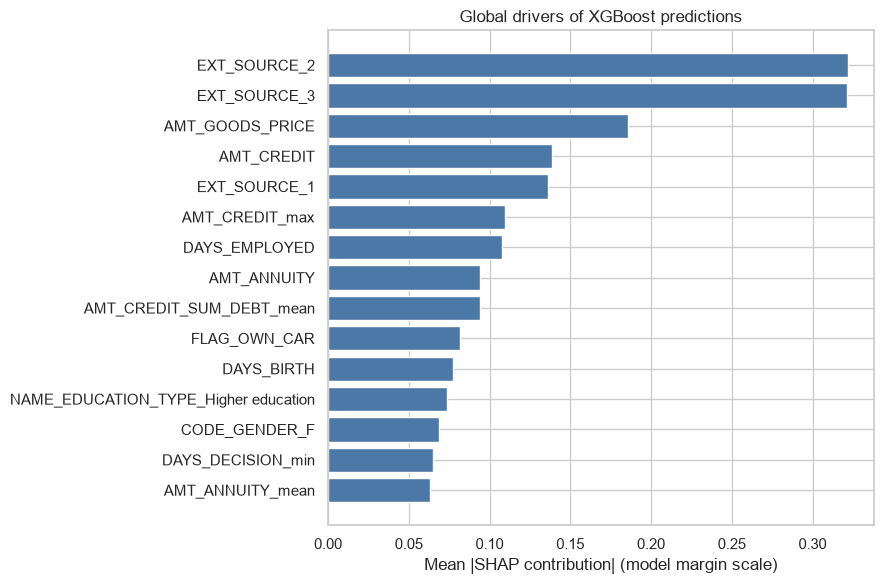

In [17]:
top_shap = mean_abs_shap.head(15).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_shap.index, top_shap.values, color="#4C78A8")
ax.set_xlabel("Mean |SHAP contribution| (model margin scale)")
ax.set_title("Global drivers of XGBoost predictions")
plt.tight_layout()
plt.show()


> **Executive takeaway.** Global contributions summarize which fields most influence predictions across the sample. The project highlights `EXT_SOURCE_2`, `EXT_SOURCE_3`, goods price, credit amount, employment duration, and bureau aggregates; the refreshed ranking is shown above.


## 6. Modular Pipeline Export & Artifact Savings | حفظ مخرجات النموذج

Save the refitted model, training-only imputer, feature schema, decision threshold, and cost assumptions under `models/`. Keep generated binary artifacts out of source control unless the repository explicitly intends to publish them. The repository's `src/` modules and `predict.py` provide the inference entry point.


In [18]:
model_path = MODELS_DIR / "credit_risk_xgb.pkl"
imputer_path = MODELS_DIR / "imputer.pkl"
features_path = MODELS_DIR / "feature_names.pkl"
metadata_path = MODELS_DIR / "decision_metadata.json"

joblib.dump(best_xgb, model_path)
joblib.dump(imputer, imputer_path)
joblib.dump(feature_names, features_path)
metadata = {
    "decision_threshold": business_threshold,
    "reference_threshold": BUSINESS_THRESHOLD_REFERENCE,
    "validation_roc_auc": float(results["Tuned XGBoost"]),
    "projected_portfolio_value": float(projected_value),
    "portfolio_size_assumption": PORTFOLIO_SIZE,
    "cost_matrix_per_applicant": COSTS,
    "feature_count": len(feature_names),
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved artifacts:")
for path in (model_path, imputer_path, features_path, metadata_path):
    print(f" • {path.relative_to(ROOT)} ({path.stat().st_size:,} bytes)")


Saved artifacts:
 • models\credit_risk_xgb.pkl (485,561 bytes)
 • models\imputer.pkl (9,319 bytes)
 • models\feature_names.pkl (6,621 bytes)
 • models\decision_metadata.json (348 bytes)


### Closing note | خلاصة تنفيذية

This workflow connects predictive ranking to an explicit financial decision rule and persists the components required to reproduce inference. Before operational use, validate the cost assumptions with business owners, measure performance on a time-based or external holdout, and monitor calibration, approval rates, and subgroup outcomes.
